# Clustering — Implementation Cheatsheet

Theory: [clustering.md](clustering.md) · Metrics: [evaluation_metrics.md](../01_toolkit/evaluation_metrics.md)

All 5 models on **one dataset** (Customer Personality, 2,240 customers) so they can be compared side by side.

| # | Section |
|---|---|
| 1 | Setup & data |
| 2 | Cleaning |
| 3 | Preparation: one-hot → scale → PCA |
| 4 | K-Means |
| 5 | K-Medoids |
| 6 | Hierarchical |
| 7 | GMM |
| 8 | DBSCAN |
| 9 | Model comparison |
| 10 | Profiling the chosen model |

## 1. Setup & data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, cophenet, dendrogram
from scipy.spatial.distance import pdist
import kmedoids

pd.set_option("display.max_columns", None)
SEED = 0
K_RANGE = range(2, 11)

In [2]:
data = pd.read_csv("../data/customer_personality.csv", sep="\t")
print(data.shape)
data.head()

(2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


## 2. Cleaning
Typical steps; the *why* behind each one is in [clustering.md](clustering.md#the-workflow-same-for-every-model).

In [3]:
df = data.copy()

# Drop the ID and the constant columns (they add no information)
df = df.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])

# Date -> enrollment year
df["Dt_Customer"] = df["Dt_Customer"].str[-4:].astype(int)

# Missing values: median (robust to outliers) for a skewed numeric column
df["Income"] = df["Income"].fillna(df["Income"].median())

# Duplicates (only visible after dropping the ID)
df = df.drop_duplicates()

# Impossible outliers: born before 1900 but enrolled in 2012+
df = df[df["Year_Birth"] >= 1939]

# Group rare categories
df["Marital_Status"] = df["Marital_Status"].replace({"Alone": "Single", "YOLO": "Other", "Absurd": "Other"})

df = df.reset_index(drop=True)
print(df.shape)

(2055, 26)


## 3. Preparation: one-hot → scale → PCA
- **One-hot** the categoricals.
- **Scale** the numeric columns (distance-based models need it).
- **PCA**: keep the fewest components that explain ≥ 80% of the variance.

In [4]:
num_cols = df.select_dtypes("number").columns
cat_cols = df.select_dtypes(exclude="number").columns

X_num = pd.DataFrame(StandardScaler().fit_transform(df[num_cols]), columns=num_cols)
X_cat = pd.get_dummies(df[cat_cols]).astype(int)
X = pd.concat([X_num, X_cat], axis=1)
X.shape

(2055, 35)

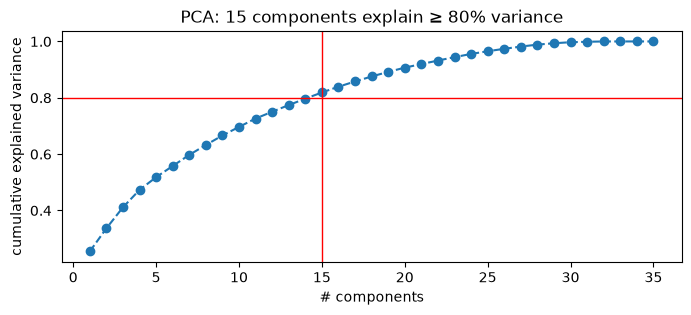

(2055, 15)

In [5]:
pca_full = PCA(random_state=SEED).fit(X)
cum_var = pca_full.explained_variance_ratio_.cumsum()
n_pc = int(np.argmax(cum_var >= 0.80) + 1)

plt.figure(figsize=(8, 3))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker="o", ls="--")
plt.axhline(0.80, color="red", lw=1)
plt.axvline(n_pc, color="red", lw=1)
plt.title(f"PCA: {n_pc} components explain ≥ 80% variance")
plt.xlabel("# components"); plt.ylabel("cumulative explained variance")
plt.show()

X_pca = PCA(n_components=n_pc, random_state=SEED).fit_transform(X)
X_pca.shape

Helper: plot a metric vs k (used by every model below).

In [6]:
def plot_vs_k(scores: dict, title: str, ylabel: str):
    plt.figure(figsize=(7, 3))
    plt.plot(list(scores.keys()), list(scores.values()), marker="o", ls="--")
    plt.title(title); plt.xlabel("k"); plt.ylabel(ylabel); plt.grid(alpha=.3)
    plt.show()

## 4. K-Means
Choose k with **Elbow (WCSS)** + **Silhouette**.

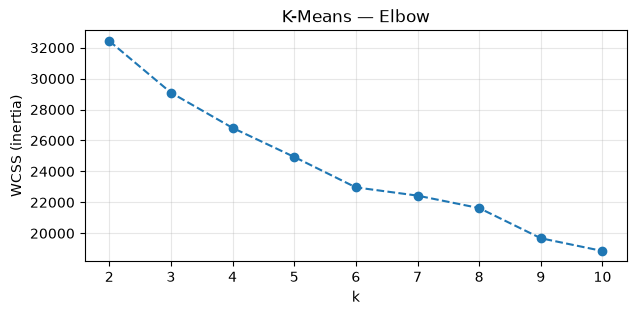

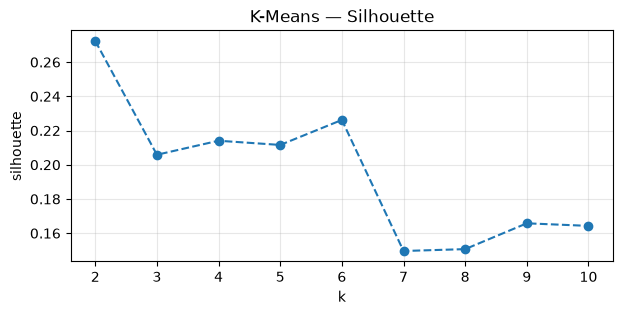

In [7]:
wcss, sil = {}, {}
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(X_pca)
    wcss[k] = km.inertia_
    sil[k] = silhouette_score(X_pca, km.labels_)

plot_vs_k(wcss, "K-Means — Elbow", "WCSS (inertia)")
plot_vs_k(sil, "K-Means — Silhouette", "silhouette")

In [8]:
kmeans = KMeans(n_clusters=3, random_state=SEED, n_init=10).fit(X_pca)
labels_kmeans = kmeans.labels_

## 5. K-Medoids
Same as K-Means but the centers are real points, so it is more robust to outliers. Uses the `kmedoids` package.

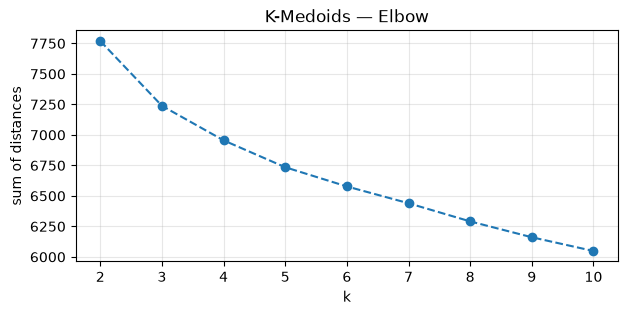

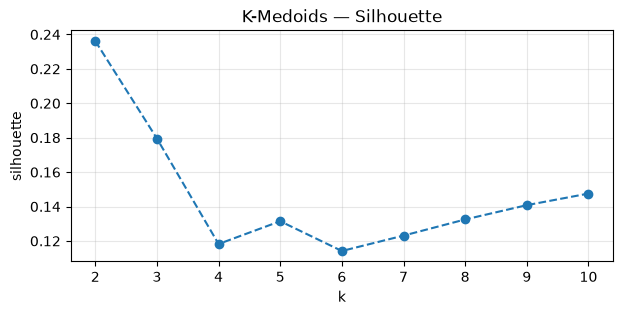

In [9]:
wcss, sil = {}, {}
for k in K_RANGE:
    kmd = kmedoids.KMedoids(n_clusters=k, metric="euclidean", method="fasterpam", random_state=SEED).fit(X_pca)
    wcss[k] = kmd.inertia_
    sil[k] = silhouette_score(X_pca, kmd.labels_)

plot_vs_k(wcss, "K-Medoids — Elbow", "sum of distances")
plot_vs_k(sil, "K-Medoids — Silhouette", "silhouette")

In [10]:
labels_kmedoids = kmedoids.KMedoids(n_clusters=3, metric="euclidean", method="fasterpam", random_state=SEED).fit(X_pca).labels_

## 6. Hierarchical (Agglomerative)
1. Find the best **distance + linkage** pair with the **cophenetic correlation**.
2. Cut the tree (choose k) with **silhouette**.
3. Check **cluster sizes**: the "best" cophenetic pair can still give useless clusters.

In [11]:
results = []
for metric in ["euclidean", "cityblock", "chebyshev"]:
    for method in ["single", "complete", "average", "weighted"]:
        Z = linkage(X_pca, method=method, metric=metric)
        c, _ = cophenet(Z, pdist(X_pca, metric=metric))
        results.append((metric, method, round(c, 3)))

# Ward only works with euclidean
Z = linkage(X_pca, method="ward")
results.append(("euclidean", "ward", round(cophenet(Z, pdist(X_pca))[0], 3)))

pd.DataFrame(results, columns=["distance", "linkage", "cophenetic"]).sort_values("cophenetic", ascending=False)

,distance,linkage,cophenetic
6,cityblock,average,0.868
2,euclidean,average,0.866
4,cityblock,single,0.843
10,chebyshev,average,0.790
0,euclidean,single,0.780
3,euclidean,weighted,0.779
7,cityblock,weighted,0.766
5,cityblock,complete,0.750
8,chebyshev,single,0.648
12,euclidean,ward,0.561


In [12]:
# Best cophenetic pair (average) vs ward: compare cluster sizes for k=3
for link in ["average", "ward"]:
    lab = AgglomerativeClustering(n_clusters=3, linkage=link).fit_predict(X_pca)
    print(f"{link:8s} sizes: {np.bincount(lab)}")

average  sizes: [2024    5   26]
ward     sizes: [588 637 830]


`average` has the best cophenetic score but puts almost everyone in one cluster. **Ward** gives usable, balanced groups, so we tune k with ward.

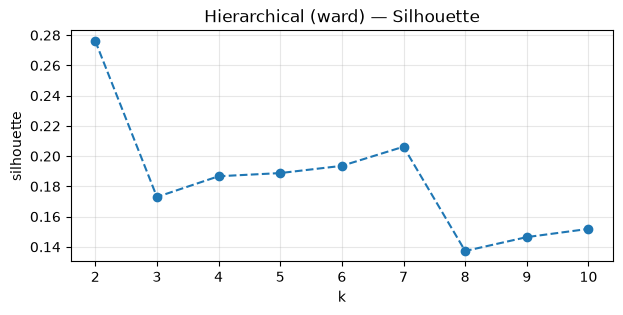

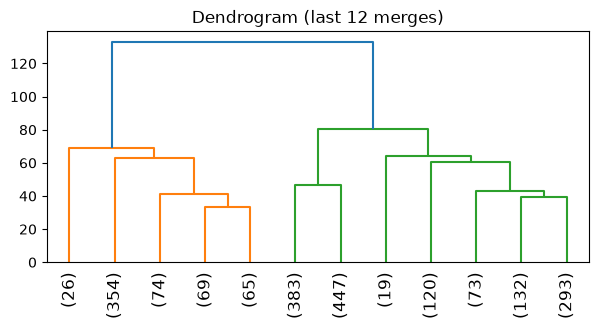

In [13]:
sil = {k: silhouette_score(X_pca, AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_pca))
       for k in K_RANGE}
plot_vs_k(sil, "Hierarchical (ward) — Silhouette", "silhouette")

Z_ward = linkage(X_pca, method="ward")
plt.figure(figsize=(7, 3))
dendrogram(Z_ward, truncate_mode="lastp", p=12, leaf_rotation=90)
plt.title("Dendrogram (last 12 merges)"); plt.show()

In [14]:
labels_hc = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X_pca)

## 7. Gaussian Mixture Model (GMM)
Choose k with **BIC / AIC (lower = better)**, then check the silhouette.

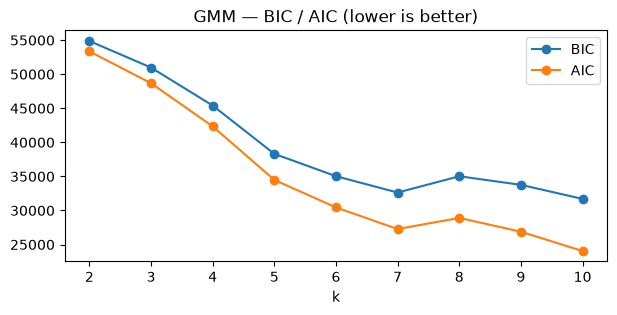

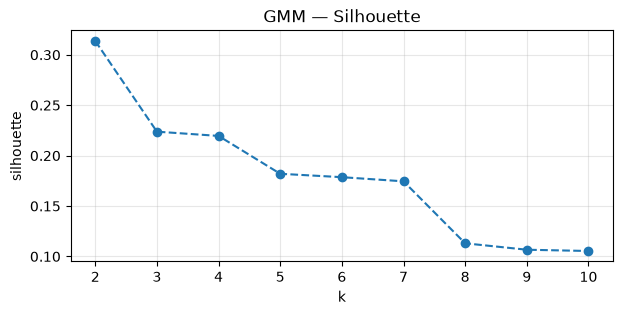

k with min BIC: 10


In [15]:
bic, aic, sil = {}, {}, {}
for k in K_RANGE:
    gmm = GaussianMixture(n_components=k, random_state=SEED).fit(X_pca)
    bic[k], aic[k] = gmm.bic(X_pca), gmm.aic(X_pca)
    sil[k] = silhouette_score(X_pca, gmm.predict(X_pca))

plt.figure(figsize=(7, 3))
plt.plot(list(bic), list(bic.values()), marker="o", label="BIC")
plt.plot(list(aic), list(aic.values()), marker="o", label="AIC")
plt.title("GMM — BIC / AIC (lower is better)"); plt.xlabel("k"); plt.legend(); plt.show()
plot_vs_k(sil, "GMM — Silhouette", "silhouette")
print("k with min BIC:", min(bic, key=bic.get))

In [16]:
gmm = GaussianMixture(n_components=3, random_state=SEED).fit(X_pca)
labels_gmm = gmm.predict(X_pca)
# Soft clustering: probability of each cluster per customer
gmm.predict_proba(X_pca)[:3].round(3)

array([[0.   , 0.003, 0.997],
       [1.   , 0.   , 0.   ],
       [0.   , 0.   , 1.   ]])

## 8. DBSCAN
No k needed. Tune `eps` × `min_samples` with silhouette. Label `-1` = noise / outlier.

In [17]:
results = []
for eps in [1, 2, 3, 4, 5]:
    for min_samples in [5, 10, 15, 20]:
        lab = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_pca)
        n_clusters = len(set(lab)) - (1 if -1 in lab else 0)
        if n_clusters > 1 or (n_clusters == 1 and -1 in lab):
            results.append((eps, min_samples, n_clusters, (lab == -1).sum(), silhouette_score(X_pca, lab)))

dbscan_grid = pd.DataFrame(results, columns=["eps", "min_samples", "n_clusters", "n_noise", "silhouette"])
dbscan_grid.sort_values("silhouette", ascending=False).head()

,eps,min_samples,n_clusters,n_noise,silhouette
18,5,15,1,57,0.503263
19,5,20,1,57,0.503263
17,5,10,2,36,0.500976
16,5,5,3,17,0.497938
13,4,10,2,92,0.421000


In [18]:
best = dbscan_grid.loc[dbscan_grid["silhouette"].idxmax()]
labels_dbscan = DBSCAN(eps=best["eps"], min_samples=int(best["min_samples"])).fit_predict(X_pca)
pd.Series(labels_dbscan).value_counts()

 0    1998
-1      57
Name: count, dtype: int64

High silhouette, but it is just **one dense blob + noise**. That is useful for **outlier detection**, not for segmentation.

## 9. Model comparison
Silhouette **and** cluster sizes **and** business sense.

In [19]:
all_labels = {
    "K-Means (k=3)": labels_kmeans,
    "K-Medoids (k=3)": labels_kmedoids,
    "Hierarchical ward (k=3)": labels_hc,
    "GMM (k=3)": labels_gmm,
    "DBSCAN": labels_dbscan,
}
comparison = pd.DataFrame({
    name: {"silhouette": round(silhouette_score(X_pca, lab), 3),
           "sizes": sorted(np.bincount(lab - lab.min()).tolist(), reverse=True)}
    for name, lab in all_labels.items()
}).T
comparison

,silhouette,sizes
K-Means (k=3),0.206,"[954, 603, 498]"
K-Medoids (k=3),0.18,"[847, 605, 603]"
Hierarchical ward (k=3),0.173,"[830, 637, 588]"
GMM (k=3),0.224,"[1062, 754, 239]"
DBSCAN,0.503,"[1998, 57]"


**How to read it**
- **DBSCAN** has the highest silhouette (~0.50), but it only finds 1 cluster + noise, so it gives no segments.
- **GMM** scores slightly higher than K-Means (~0.22 vs ~0.21), but one of its clusters is much smaller.
- The scores are all low (~0.2), which means the groups overlap. That is normal with real customer data.
- **K-Means** is chosen: about the same score, more balanced sizes, and the easiest to explain. Low scores are a reason to rely on **business sense** when you choose.

## 10. Profiling the chosen model
Always profile on the **original** columns, never on the PCA components.

In [20]:
profile = df.copy()
profile["Cluster"] = labels_kmeans

profile["Cluster"].value_counts().sort_index()

Cluster
0    603
1    498
2    954
Name: count, dtype: int64

In [21]:
key_cols = ["Income", "Year_Birth", "Kidhome", "Teenhome", "Recency",
            "MntWines", "MntMeatProducts", "MntGoldProds",
            "NumDealsPurchases", "NumWebPurchases", "NumStorePurchases", "NumWebVisitsMonth", "Response"]
means = profile.groupby("Cluster")[key_cols].mean()
means.round(1)

,Income,Year_Birth,Kidhome,Teenhome,Recency,MntWines,MntMeatProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumStorePurchases,NumWebVisitsMonth,Response
Cluster,,,,,,,,,,,,,
0,58135.0,1964.4,0.2,0.9,48.3,464.4,140.1,61.9,3.7,6.4,7.7,5.7,0.1
1,77927.3,1968.7,0.0,0.1,49.0,610.4,476.2,76.4,1.2,5.1,8.3,2.8,0.3
2,35309.6,1971.8,0.8,0.4,49.4,42.6,24.0,15.4,2.1,2.1,3.2,6.4,0.1


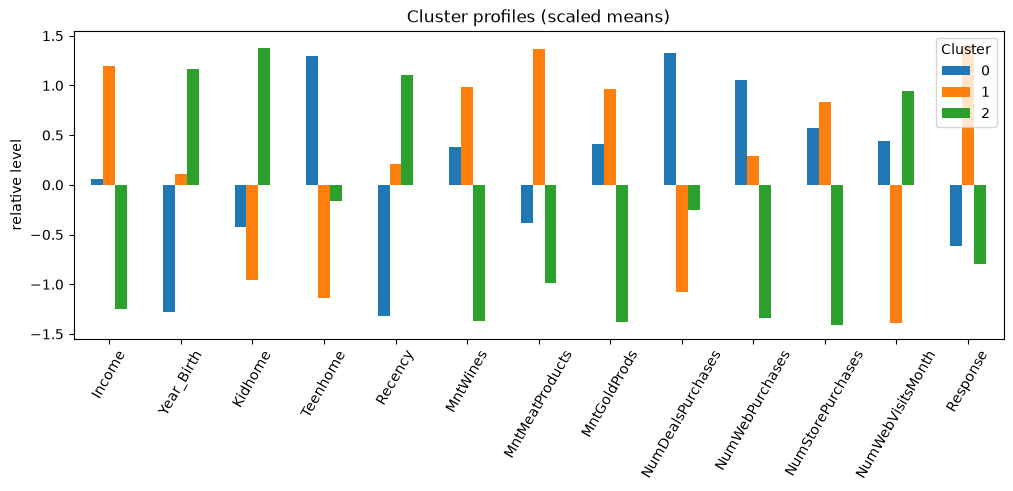

In [22]:
means_scaled = pd.DataFrame(StandardScaler().fit_transform(means), index=means.index, columns=key_cols)
means_scaled.T.plot(kind="bar", figsize=(12, 4))
plt.title("Cluster profiles (scaled means)"); plt.ylabel("relative level"); plt.xticks(rotation=60)
plt.show()

**Give each cluster a business name and an action** (read from the means table above):

| Profile | Description | Action |
|---|---|---|
| **Affluent spenders** | Highest income (~78k), no kids, highest spend on wine & meat, few deals, best campaign response | Premium / loyalty program |
| **Established families** | Middle income (~58k), teens at home, good spend, **most deal purchases** and web purchases | Discounts, bundles, web promos |
| **Budget young families** | Lowest income (~35k), small kids, very low spend, many web visits but few purchases | Low-price offers, convert web visits |

*(Cluster numbers 0/1/2 can change between runs or library versions, so always match profiles by their means, not by number.)*